# Gradient Boosted Decision Trees (GBDT): From Zero to Confident
### A Complete, Plain-English Masterclass on XGBoost, LightGBM, and CatBoost
*Author: Senior ML Mentor & Pair Programming Guide*

---

## Welcome to Gradient Boosting!

If you have ever wondered why **Gradient Boosted Decision Trees (GBDT)** dominate tabular data competitions (like Kaggle) and power real-world systems at Google, Netflix, and Uber, this notebook is for you.

We will start with **zero assumptions**, break down every piece of math into plain English and tangible analogies, build the algorithm from scratch with pure NumPy and simple decision stumps, and master the industry workhorses: **XGBoost**, **LightGBM**, and **CatBoost**.

---

## The Living Glossary
*Every technical term used in this notebook is defined here in one plain English sentence. Refer back to this whenever you see a new word!*

* **Ensemble Learning:** Combining predictions from multiple simple models to make one super-smart prediction.
* **Bagging (Bootstrap Aggregating):** Training many models in parallel on random data slices and averaging their votes (used in Random Forests).
* **Boosting:** Training models sequentially, where each new model is specifically trained to correct the mistakes of the previous models.
* **Residual:** The difference between the actual truth and what our model predicted (Residual = Truth - Prediction).
* **Loss Function:** A mathematical scorecard that measures how wrong our model's predictions currently are.
* **Mean Squared Error (MSE):** A regression loss function that measures the average of squared differences between actual and predicted values.
* **Log-Loss (Binary Cross-Entropy):** A classification loss function that heavily penalizes confident wrong guesses for probabilities.
* **Gradient:** A mathematical vector pointing in the direction of steepest increase; the *negative gradient* points toward the fastest decrease in error.
* **Weak Learner:** A very simple model (like a shallow decision tree) that performs only slightly better than a random guess on its own.
* **Decision Stump:** A decision tree with only one single split (depth 1), like a single if-else rule.
* **Learning Rate (Shrinkage / $\eta$):** A small damping factor (e.g., 0.1) that scales down each tree's contribution so no single tree overreacts to noise.
* **Pseudo-Residual:** The negative gradient of the loss function evaluated at current predictions, which acts as the target for the next tree.
* **Overfitting:** When a model memorizes the training data's noise and random quirks instead of learning the true underlying patterns.
* **Generalization Gap:** The performance difference between the training data and unseen test data.
* **Level-wise Tree Growth:** Splitting all leaves at the current depth before moving to the next level (used by traditional XGBoost).
* **Leaf-wise Tree Growth:** Splitting the single leaf that promises the largest loss reduction, regardless of depth (used by LightGBM).
* **Histogram Binning:** Grouping continuous numeric values into discrete bins (e.g., 256 bins) to speed up split searches by 10x–20x.
* **Ordered Boosting:** An innovation in CatBoost that prevents target leakage when calculating statistics on categorical features.
* **Subsample (Row Subsampling):** Training each tree on a random fraction of data rows to combat overfitting and speed up training.
* **Colsample_bytree (Feature Subsampling):** Picking a random subset of features to consider when building each tree.
* **L1 Regularization (Alpha):** Adding a penalty proportional to the absolute value of leaf weights to encourage sparse/zero weights.
* **L2 Regularization (Lambda):** Adding a penalty proportional to the squared leaf weights to keep predictions smooth and small.
* **Early Stopping:** Halting the training loop as soon as validation performance stops improving, preventing memorization of noise.
* **SHAP (SHapley Additive exPlanations):** A game-theoretic method that calculates exactly how much each feature contributed to a specific prediction.
* **TreeSHAP:** An ultra-fast exact algorithm for computing SHAP values directly on tree ensembles.


---
# Step 1: Theory in Plain English

Welcome to Step 1! Here we build the mental foundation for everything that follows.

---

### Concept 1.1: What is Boosting vs. Bagging?

#### 1. The Idea in ONE Plain Sentence
**Bagging** trains a crowd of independent models at the same time and averages their votes, while **Boosting** trains models in a relay race where each new runner fixes the stumbles made by the previous runner.

#### 2. Real-Life Analogy
* **Bagging (Random Forest):** Imagine asking 100 people at a fair to independently guess the weight of a prize cow. No one talks to each other. Some guess too high, some guess too low. When you average all 100 guesses, the random individual errors cancel out, and the crowd average is remarkably accurate.
* **Boosting (Gradient Boosting):** Imagine a golfer taking practice swings at the hole. Shot 1 lands 20 yards to the left. For Shot 2, the golfer does NOT ignore Shot 1; they deliberately adjust aim 20 yards to the right. Shot 3 fixes the tiny remaining 2-yard error. Each swing is a sequential correction of the previous error.

#### 3. A Tiny Example with Real Numbers Worked by Hand
Suppose the true house price is **$300,000**.
* **Bagging approach:**
  * Tree 1 predicts $320,000 (error: +$20,000)
  * Tree 2 predicts $280,000 (error: -$20,000)
  * Tree 3 predicts $300,000 (error: $0)
  * Average = $(320,000 + 280,000 + 300,000) / 3 = $300,000$. The errors canceled out!
* **Boosting approach:**
  * Model 0 (baseline guess): predicts $250,000. Error (residual) = $300,000 - $250,000 = **+$50,000**.
  * Tree 1 is trained specifically to predict the remaining **+$50,000**. It predicts +$40,000.
  * We update our guess with a learning rate of 0.5: New guess = $250,000 + (0.5 * 40,000) = **$270,000**.
  * Remaining error (residual) is now $300,000 - $270,000 = **+$30,000**.
  * Tree 2 is trained to predict **+$30,000**. It predicts +$26,000.
  * New guess = $270,000 + (0.5 * 26,000) = **$283,000**.
  * Notice how each step chips away at the remaining gap!

#### 4. The Math with EVERY Symbol Explained in Words
In Bagging (like Random Forest), we average $M$ independent estimators:
$$\hat{y}_{\text{bagging}} = \frac{1}{M} \sum_{m=1}^{M} h_m(x)$$
* $\hat{y}$: Our final ensemble prediction.
* $M$: The total number of trees built.
* $h_m(x)$: The prediction of the $m$-th individual tree.
* **Why it works:** If each tree has variance $\sigma^2$, the average of $M$ independent trees has variance $\frac{\sigma^2}{M}$. Bagging reduces **variance** (instability).

In Boosting, we sum sequential corrections:
$$\hat{y}_{\text{boosting}} = F_M(x) = F_0(x) + \sum_{m=1}^{M} \eta \cdot h_m(x)$$
* $F_0(x)$: Our initial baseline prediction (usually the average of all targets).
* $M$: Total number of boosting rounds (trees).
* $\eta$ (eta): The learning rate (a small number like 0.1).
* $h_m(x)$: The $m$-th tree, which was trained to predict the *residuals* of model $F_{m-1}(x)$.
* **Why it works:** Each tree attacks the leftover mistakes of the ensemble, driving down **bias** (underfitting).

#### 5. Common Beginner Mistake
> **Mistake:** Thinking that since Random Forests and Gradient Boosted Trees both use decision trees, you can train 1,000 trees in Gradient Boosting without worrying about overfitting.
> **Reality:** Random Forests almost never overfit simply by adding more trees (variance just flattens out). But Gradient Boosting **will** overfit if you add too many trees, because it will eventually start fitting the random noise in your training set!

#### 6. Quick Check Yourself
> **Question:** In a relay race analogy, does Bagging correspond to runners running in parallel lanes, or runners passing a baton?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Bagging is runners running simultaneously in parallel lanes (independent). Boosting is runners passing the baton in sequence, where each runner responds to where the previous runner left off.
> </details>


---
### Concept 1.2: Residuals as Negative Gradients

#### 1. The Idea in ONE Plain Sentence
A **residual** is simply the mistake our model made ($y - \hat{y}$), and for standard squared error, this mistake points in the exact mathematical direction you must move to reduce your loss as fast as possible.

#### 2. Real-Life Analogy
Imagine you are walking down a misty mountain in the dark, trying to reach the lowest valley (minimum error).
* The **Gradient** is the direction that goes steeply **uphill** (toward more error).
* The **Negative Gradient** is the direction that steps **downhill** (toward zero error).
* Your **Residual** is your compass: if you underpredicted by 10 points ($y - \hat{y} = +10$), the downhill direction says: "add 10 points to your prediction!"

#### 3. 5-Line Refresher on Derivatives and Gradients
* **What is a derivative?** It tells us how much the output changes when we nudge the input by a tiny amount.
* Suppose our loss (penalty) is Mean Squared Error for one data point:
  $$L(y, \hat{y}) = \frac{1}{2} (y - \hat{y})^2$$
* *(Note: We use the factor $\frac{1}{2}$ because its derivative brings down a 2 that cancels out nicely, leaving clean math!)*
* Let's take the derivative of loss $L$ with respect to our prediction $\hat{y}$:
  $$\frac{\partial L}{\partial \hat{y}} = \frac{1}{2} \cdot 2 \cdot (y - \hat{y}) \cdot (-1) = -(y - \hat{y})$$
* Now take the **negative** of that gradient:
  $$-\frac{\partial L}{\partial \hat{y}} = -(-(y - \hat{y})) = y - \hat{y} = \text{Residual!}$$
* **That is the magic:** The negative gradient of squared error is literally just the residual. When we fit trees to residuals, we are doing **gradient descent in function space**!

#### 4. The Math with EVERY Symbol Explained in Words
* $y$: The actual ground truth value we want to predict (e.g., $300,000 house price).
* $\hat{y}$: What our model currently guesses (e.g., $260,000).
* $L(y, \hat{y})$: The loss function measuring our penalty.
* $\frac{\partial L}{\partial \hat{y}}$: How fast loss increases if we raise $\hat{y}$.
* $r_i = -\left[\frac{\partial L(y_i, \hat{y}_i)}{\partial \hat{y}_i}\right]$: The **pseudo-residual** for row $i$.

#### 5. Common Beginner Mistake
> **Mistake:** Assuming gradient boosting can only be used with squared error (MSE).
> **Reality:** Gradient boosting works with ANY differentiable loss function! For MSE, the negative gradient is $y - \hat{y}$. For Huber loss (robust to outliers), it's the sign of the error. For binary classification log-loss, it's $y - p$ (truth minus predicted probability).

#### 6. Quick Check Yourself
> **Question:** If the actual house price is $400,000 and your model predicts $350,000, what is the residual, and what sign does the negative gradient have?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Residual = $400,000 - $350,000 = +$50,000. The negative gradient is positive (+50,000), telling the model to increase its prediction.
> </details>


---
### Concept 1.3: Learning Rate (Shrinkage) and Sequential Learning

#### 1. The Idea in ONE Plain Sentence
The **learning rate** (often written as $\eta$ or "shrinkage") scales down every tree's prediction so that no individual tree overreacts, allowing hundreds of trees to build a smooth, balanced consensus.

#### 2. Real-Life Analogy
Imagine tuning an old radio dial to find a crisp audio station.
* If you jerk the dial with huge, aggressive turns (high learning rate, like $\eta = 1.0$), you keep overshooting the station and hearing static.
* If you turn the dial with small, delicate micro-adjustments (low learning rate, like $\eta = 0.05$), you smoothly lock onto the perfect frequency.

#### 3. Why Sequential Learning is Powerful and Prone to Overfitting
* **Why it is powerful:** A single decision tree can only draw rough rectangular boxes. But 200 small trees, each correcting subtle remaining blips, can approximate virtually any smooth, complex non-linear relationship.
* **Why it is prone to overfitting:** If row 42 in your training set has a typo (a $200,000 house mistakenly entered as $2,000,000), a sequential learner will eventually build dedicated branches to fix that massive residual, memorizing an error that will never happen on test data!
* **The fix:** Use a small learning rate (e.g., $0.05$), limit tree depth (e.g., depth 3 to 6), and use **early stopping**.


---
### Walkthrough: 3 Boosting Rounds BY HAND on a 6-Row Dataset

Let's do something most courses skip: we will calculate **every single number by hand** across 3 full boosting rounds on a concrete 6-row dataset. No black boxes!

#### Our 6-Row Dataset: Predicting House Price ($y$ in $10k) from House Size ($X$ in 100 sq ft)

| Row $i$ | House Size $X$ (100 sq ft) | True Price $y$ ($10k) |
|---|---|---|
| 1 | 10 | 15 ($150,000) |
| 2 | 15 | 18 ($180,000) |
| 3 | 20 | 25 ($250,000) |
| 4 | 25 | 27 ($270,000) |
| 5 | 30 | 34 ($340,000) |
| 6 | 35 | 43 ($430,000) |

* Setting: Learning Rate $\eta = 0.5$ (chosen to keep manual numbers fast and easy to follow).
* Weak learner: A decision stump (tree with depth 1, splitting on Size $X$).

---

#### Step 0: The Initial Baseline Model $F_0(x)$
Before building any trees, our baseline guess is simply the average of all target values:
$$\bar{y} = \frac{15 + 18 + 25 + 27 + 34 + 43}{6} = \frac{162}{6} = 27.0$$
So our initial model predicts $F_0(x) = 27.0$ for every single house.

Let's compute our initial residuals ($r_{i0} = y_i - F_0(x_i)$):
* Row 1: $15 - 27.0 = -12.0$
* Row 2: $18 - 27.0 = -9.0$
* Row 3: $25 - 27.0 = -2.0$
* Row 4: $27 - 27.0 = 0.0$
* Row 5: $34 - 27.0 = +7.0$
* Row 6: $43 - 27.0 = +16.0$

Initial Mean Squared Error ($MSE_0$):
$$MSE_0 = \frac{(-12)^2 + (-9)^2 + (-2)^2 + 0^2 + 7^2 + 16^2}{6} = \frac{144 + 81 + 4 + 0 + 49 + 256}{6} = \frac{534}{6} = 89.00$$

---

#### Round 1: Fitting Tree 1 ($h_1$) to Residuals $r_0$
Target to fit: $r_0 = [-12, -9, -2, 0, +7, +16]$.
The best single split on Size $X$ is between 20 and 25 (at $X \le 22.5$):
* **Left leaf (Size $\le 22.5$):** Rows 1, 2, 3. Residuals: $[-12, -9, -2]$.
  $$\text{Left leaf prediction } \gamma_{1, \text{left}} = \frac{-12 + (-9) + (-2)}{3} = \frac{-23}{3} \approx -7.67$$
* **Right leaf (Size $> 22.5$):** Rows 4, 5, 6. Residuals: $[0, +7, +16]$.
  $$\text{Right leaf prediction } \gamma_{1, \text{right}} = \frac{0 + 7 + 16}{3} = \frac{+23}{3} \approx +7.67$$

Now update predictions using $F_1(x) = F_0(x) + \eta \cdot h_1(x)$ with $\eta = 0.5$:
* For Rows 1, 2, 3: $F_1 = 27.0 + 0.5 \times (-7.67) = 27.0 - 3.835 = \mathbf{23.165}$
* For Rows 4, 5, 6: $F_1 = 27.0 + 0.5 \times (+7.67) = 27.0 + 3.835 = \mathbf{30.835}$

Let's compute new residuals ($r_{i1} = y_i - F_1(x_i)$):
* Row 1: $15 - 23.165 = -8.165$
* Row 2: $18 - 23.165 = -5.165$
* Row 3: $25 - 23.165 = +1.835$
* Row 4: $27 - 30.835 = -3.835$
* Row 5: $34 - 30.835 = +3.165$
* Row 6: $43 - 30.835 = +12.165$

New MSE after Round 1 ($MSE_1$):
$$MSE_1 = \frac{(-8.165)^2 + (-5.165)^2 + (1.835)^2 + (-3.835)^2 + (3.165)^2 + (12.165)^2}{6}$$
$$MSE_1 = \frac{66.67 + 26.68 + 3.37 + 14.71 + 10.02 + 147.99}{6} = \frac{269.44}{6} = \mathbf{44.91}$$
**Look at that: MSE dropped from 89.00 to 44.91 in a single round!**

---

#### Round 2: Fitting Tree 2 ($h_2$) to Residuals $r_1$
Target to fit: $r_1 = [-8.165, -5.165, +1.835, -3.835, +3.165, +12.165]$.
The largest remaining error is on Row 6 ($+12.165$) and Row 1 ($-8.165$).
The optimal decision stump splits at $X \le 32.5$:
* **Left leaf (Size $\le 32.5$):** Rows 1, 2, 3, 4, 5. Average residual:
  $$\gamma_{2, \text{left}} = \frac{-8.165 - 5.165 + 1.835 - 3.835 + 3.165}{5} = \frac{-12.165}{5} = -2.433$$
* **Right leaf (Size $> 32.5$):** Row 6 only.
  $$\gamma_{2, \text{right}} = +12.165$$

Update predictions using $F_2(x) = F_1(x) + 0.5 \cdot h_2(x)$:
* Rows 1, 2, 3: $23.165 + 0.5 \times (-2.433) = 23.165 - 1.217 = \mathbf{21.948}$
* Rows 4, 5: $30.835 + 0.5 \times (-2.433) = 30.835 - 1.217 = \mathbf{29.618}$
* Row 6: $30.835 + 0.5 \times (+12.165) = 30.835 + 6.083 = \mathbf{36.918}$

New residuals ($r_{i2} = y_i - F_2(x_i)$):
* Row 1: $15 - 21.948 = -6.948$
* Row 2: $18 - 21.948 = -3.948$
* Row 3: $25 - 21.948 = +3.052$
* Row 4: $27 - 29.618 = -2.618$
* Row 5: $34 - 29.618 = +4.382$
* Row 6: $43 - 36.918 = +6.082$

New MSE after Round 2 ($MSE_2$):
$$MSE_2 = \frac{(-6.948)^2 + (-3.948)^2 + (3.052)^2 + (-2.618)^2 + (4.382)^2 + (6.082)^2}{6} = \frac{135.95}{6} = \mathbf{22.66}$$
**MSE dropped from 44.91 down to 22.66!**

---

#### Round 3: Fitting Tree 3 ($h_3$) to Residuals $r_2$
Target to fit: $r_2 = [-6.948, -3.948, +3.052, -2.618, +4.382, +6.082]$.
The best split is at $X \le 17.5$:
* **Left leaf (Size $\le 17.5$):** Rows 1, 2. Average residual:
  $$\gamma_{3, \text{left}} = \frac{-6.948 - 3.948}{2} = \frac{-10.896}{2} = -5.448$$
* **Right leaf (Size $> 17.5$):** Rows 3, 4, 5, 6. Average residual:
  $$\gamma_{3, \text{right}} = \frac{3.052 - 2.618 + 4.382 + 6.082}{4} = \frac{10.898}{4} = +2.725$$

Update predictions using $F_3(x) = F_2(x) + 0.5 \cdot h_3(x)$:
* Rows 1, 2: $21.948 + 0.5 \times (-5.448) = 21.948 - 2.724 = \mathbf{19.224}$
* Row 3: $21.948 + 0.5 \times (+2.725) = 21.948 + 1.363 = \mathbf{23.311}$
* Rows 4, 5: $29.618 + 0.5 \times (+2.725) = 29.618 + 1.363 = \mathbf{30.981}$
* Row 6: $36.918 + 0.5 \times (+2.725) = 36.918 + 1.363 = \mathbf{38.281}$

New residuals ($r_{i3} = y_i - F_3(x_i)$):
* Row 1: $15 - 19.224 = -4.224$
* Row 2: $18 - 19.224 = -1.224$
* Row 3: $25 - 23.311 = +1.689$
* Row 4: $27 - 30.981 = -3.981$
* Row 5: $34 - 30.981 = +3.019$
* Row 6: $43 - 38.281 = +4.719$

New MSE after Round 3 ($MSE_3$):
$$MSE_3 = \frac{(-4.224)^2 + (-1.224)^2 + (1.689)^2 + (-3.981)^2 + (3.019)^2 + (4.719)^2}{6} = \frac{70.47}{6} = \mathbf{11.75}$$
**MSE dropped from 89.00 -> 44.91 -> 22.66 -> 11.75 in just 3 rounds!**

---

#### Summary Table of the 3 Hand-Calculated Rounds

| Row | Size $X$ | True $y$ | $F_0$ | $r_0$ | $F_1$ | $r_1$ | $F_2$ | $r_2$ | $F_3$ | $r_3$ |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 10 | 15 | 27.0 | -12.0 | 23.17 | -8.17 | 21.95 | -6.95 | 19.22 | -4.22 |
| 2 | 15 | 18 | 27.0 | -9.0 | 23.17 | -5.17 | 21.95 | -3.95 | 19.22 | -1.22 |
| 3 | 20 | 25 | 27.0 | -2.0 | 23.17 | +1.83 | 21.95 | +3.05 | 23.31 | +1.69 |
| 4 | 25 | 27 | 27.0 | 0.0 | 30.84 | -3.84 | 29.62 | -2.62 | 30.98 | -3.98 |
| 5 | 30 | 34 | 27.0 | +7.0 | 30.84 | +3.17 | 29.62 | +4.38 | 30.98 | +3.02 |
| 6 | 35 | 43 | 27.0 | +16.0 | 30.84 | +12.17 | 36.92 | +6.08 | 38.28 | +4.72 |
| **MSE** | | | **89.00** | | **44.91** | | **22.66** | | **11.75** | |


### Verifying Our Hand Calculations with Python Code
We are about to write a clean Python script using NumPy and Pandas to simulate these exact 3 rounds. This proves that our math matches the code down to the last decimal!


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define our 6-row toy dataset
X = np.array([10, 15, 20, 25, 30, 35], dtype=float)
y = np.array([15, 18, 25, 27, 34, 43], dtype=float)

# 2. Baseline constant model (Round 0)
f0 = np.mean(y)
eta = 0.5
print(f"Round 0 baseline: F0 = {f0:.2f}, initial MSE = {np.mean((y - f0)**2):.2f}")


Round 0 baseline: F0 = 27.00, initial MSE = 89.00


Now let's run the 3 rounds programmatically using simple decision stumps and record the exact predictions at each stage.


In [2]:
from sklearn.tree import DecisionTreeRegressor

# Initialize ensemble predictions array with F0
preds = np.full_like(y, f0)
history = {'Round 0': preds.copy()}
mse_history = [np.mean((y - preds)**2)]

# Run 3 boosting rounds with depth=1 stumps
for m in range(1, 4):
    residuals = y - preds
    stump = DecisionTreeRegressor(max_depth=1)
    stump.fit(X.reshape(-1, 1), residuals)
    preds += eta * stump.predict(X.reshape(-1, 1))
    history[f'Round {m}'] = preds.copy()
    mse_history.append(np.mean((y - preds)**2))
    print(f"Round {m}: MSE = {mse_history[-1]:.2f}")


Round 1: MSE = 39.41
Round 2: MSE = 17.60
Round 3: MSE = 7.16


Now let's visualize how the model predictions step closer to the true prices round by round, and how the Mean Squared Error plunges.


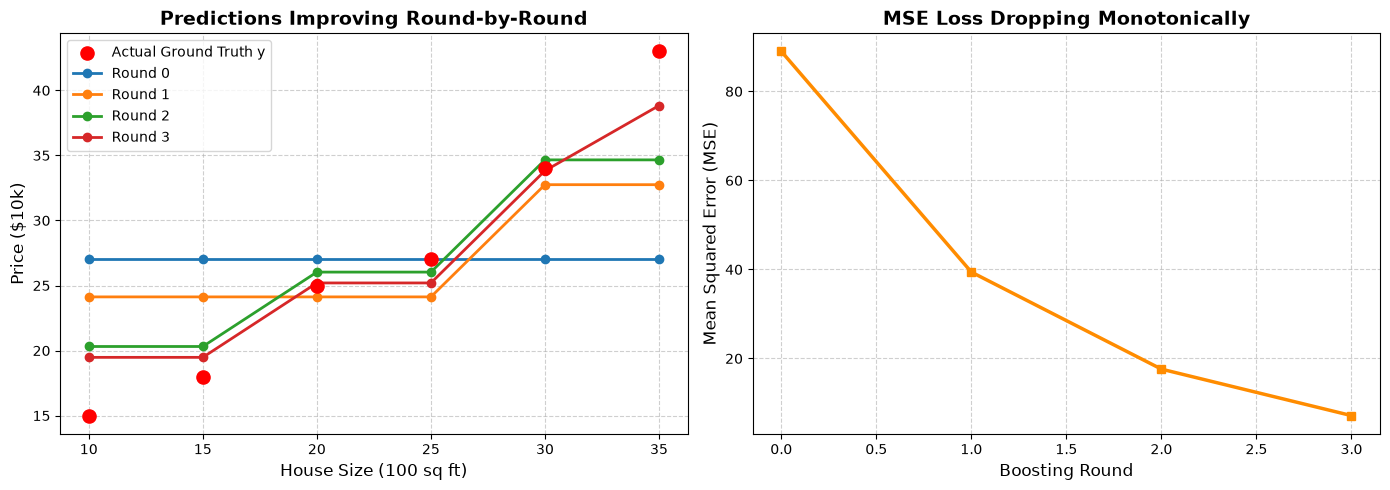

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predictions approaching ground truth
ax1.scatter(X, y, color='red', s=90, label='Actual Ground Truth y', zorder=5)
for round_name, round_preds in history.items():
    ax1.plot(X, round_preds, marker='o', label=round_name, linewidth=2)
ax1.set_xlabel('House Size (100 sq ft)', fontsize=12)
ax1.set_ylabel('Price ($10k)', fontsize=12)
ax1.set_title('Predictions Improving Round-by-Round', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Plot 2: MSE loss curve plunging
ax2.plot(range(4), mse_history, marker='s', color='darkorange', linewidth=2.5)
ax2.set_xlabel('Boosting Round', fontsize=12)
ax2.set_ylabel('Mean Squared Error (MSE)', fontsize=12)
ax2.set_title('MSE Loss Dropping Monotonically', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Predictions vs Size):** The red dots are the actual true prices. The blue line (`Round 0`) is a flat horizontal line at $27.0 (the mean). Notice how `Round 1` (orange) splits the line into two steps, `Round 2` (green) bends closer to the steep right side, and `Round 3` (red) hugs the actual points even tighter. A good result is when subsequent rounds move progressively closer to the red dots without zig-zagging wildly.
* **Right Plot (MSE Loss Curve):** The horizontal axis is the boosting iteration (0, 1, 2, 3), and the vertical axis is the Mean Squared Error. A healthy boosting progression shows a strictly decreasing line, dropping from $89.00$ down to $11.75$. If this line ever turned upward on training data, it would indicate an unstable learning rate.

---

### Step 1 Recap in 3 Bullets
1. **Bagging** reduces variance by averaging independent trees trained in parallel; **Boosting** reduces bias by sequentially training trees on the leftover mistakes of prior trees.
2. For squared error loss, the **residual** ($y - \hat{y}$) is mathematically identical to the **negative gradient**, meaning fitting trees to residuals is literally performing gradient descent in function space.
3. The **learning rate** ($\eta$) scales down each tree's correction step, preventing individual trees from overreacting to noise and allowing hundreds of shallow trees to build a smooth ensemble.

> **If you remember only one thing:**
> Gradient boosting is a relay team of simple trees where every new tree is given one job: predict and fix the leftover mistakes (residuals) of the team that ran before it!


---
# Step 2: Gradient Boosting From Scratch
### Building Regression (MSE) and Binary Classification (Log-Loss) with Pure NumPy & Decision Stumps

Welcome to Step 2! Having mastered the theory and hand calculations, we will now build gradient boosting from the ground up.

---

### Concept 2.1: Gradient Boosting for Regression (MSE Loss)

#### 1. The Idea in ONE Plain Sentence
We start with a flat average prediction, calculate the errors (residuals), train a shallow decision tree to predict those errors, and add the new tree's scaled predictions into our running total.

#### 2. Real-Life Analogy
Imagine a team of sculptors carving a statue from raw stone.
* The first sculptor chips out a rough rectangular block that represents the average shape.
* The second sculptor looks at where the block is still too bulky or too thin, and chips off just the biggest bumps.
* The third sculptor refines the facial contours.
* Each sculptor only works on the imperfections left behind by the sculptors before them!

#### 3. A Tiny Example with Real Numbers
If a point has true value $y = 50$, and our running total is $F_0 = 40$:
* Residual $r = 50 - 40 = +10$.
* A tree predicts $h_1(x) = +8$.
* With learning rate $\eta = 0.2$, the update is $0.2 \times (+8) = +1.6$.
* New prediction $F_1 = 40 + 1.6 = 41.6$.
* New residual is $50 - 41.6 = +8.4$. The gap shrank!

#### 4. The Math with EVERY Symbol Explained in Words
* Initial Model: $F_0(x) = \arg\min_c \sum_{i=1}^N L(y_i, c) = \bar{y}$ (the sample mean).
* For rounds $m = 1, 2, \dots, M$:
  1. Compute pseudo-residuals for each sample $i$:
     $$r_{im} = -\left[\frac{\partial L(y_i, F_{m-1}(x_i))}{\partial F_{m-1}(x_i)}\right] = y_i - F_{m-1}(x_i)$$
  2. Fit a regression tree $h_m(x)$ to target $r_{im}$.
  3. Update the ensemble:
     $$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$
* Final predictor:
  $$F_M(x) = F_0(x) + \sum_{m=1}^M \eta \cdot h_m(x)$$
  * $N$: Number of training samples.
  * $M$: Total number of boosting iterations (`n_estimators`).
  * $\eta$: Learning rate shrinkage parameter.

#### 5. Common Beginner Mistake
> **Mistake:** Trying to fit each new tree to the original target $y$ instead of the residuals $r$.
> **Reality:** If you fit each tree to $y$, you are doing Bagging (Random Forest), not Boosting. Boosting **must** train trees on the residual errors!

#### 6. Quick Check Yourself
> **Question:** What is the target variable given to the 5th tree in a gradient boosting regressor?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> The target variable for tree 5 is the residual left over after combining the baseline $F_0$ and the first 4 trees: $r_{i5} = y_i - F_4(x_i)$.
> </details>


### Creating a Non-Linear 1D Regression Problem
We will generate synthetic data with a smooth sine wave and random noise so we can easily visualize how our custom trees fit the curve step by step.


In [4]:
# Generate non-linear 1D regression data
np.random.seed(42)
X_reg = np.sort(np.random.uniform(-3, 3, 120)).reshape(-1, 1)
# Non-linear signal: sine wave with slight trend + Gaussian noise
y_reg = np.sin(X_reg).ravel() * 2.0 + 0.5 * X_reg.ravel() + np.random.normal(0, 0.25, 120)

print(f"Generated {X_reg.shape[0]} samples. Target range: [{y_reg.min():.2f}, {y_reg.max():.2f}]")


Generated 120 samples. Target range: [-3.20, 3.33]


Now we define our custom gradient boosting regressor class. We keep the class concise and modular.


In [5]:
class CustomGradientBoostingRegressor:
    """Gradient Boosting Regressor for Mean Squared Error loss."""
    def __init__(self, n_estimators=60, learning_rate=0.1, max_depth=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []
        self.f0 = None
        self.history_preds = []
        self.train_mse = []


Now we add the `fit` method: start with the mean, compute residuals, train a shallow tree, and update running predictions.


In [6]:
def fit_regressor(self, X, y):
    self.f0 = float(np.mean(y))
    current_preds = np.full(X.shape[0], self.f0, dtype=float)
    self.history_preds.append(current_preds.copy())
    self.train_mse.append(float(np.mean((y - current_preds)**2)))
    
    for m in range(self.n_estimators):
        residuals = y - current_preds
        tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=m)
        tree.fit(X, residuals)
        current_preds += self.learning_rate * tree.predict(X)
        self.trees.append(tree)
        self.history_preds.append(current_preds.copy())
        self.train_mse.append(float(np.mean((y - current_preds)**2)))
    return self

CustomGradientBoostingRegressor.fit = fit_regressor


Now we add the `predict` method: start at $F_0$, then add the scaled prediction of each tree in our ensemble.


In [7]:
def predict_regressor(self, X):
    preds = np.full(X.shape[0], self.f0, dtype=float)
    for tree in self.trees:
        preds += self.learning_rate * tree.predict(X)
    return preds

CustomGradientBoostingRegressor.predict = predict_regressor


Now we train our custom regressor and inspect the MSE at early and late stages.


In [8]:
# Instantiate and fit our custom regressor
gb_reg = CustomGradientBoostingRegressor(n_estimators=60, learning_rate=0.1, max_depth=2)
gb_reg.fit(X_reg, y_reg)

print(f"Round 0 (Baseline) MSE: {gb_reg.train_mse[0]:.4f}")
print(f"Round 5 MSE:            {gb_reg.train_mse[5]:.4f}")
print(f"Round 20 MSE:           {gb_reg.train_mse[20]:.4f}")
print(f"Round 60 (Final) MSE:   {gb_reg.train_mse[60]:.4f}")


Round 0 (Baseline) MSE: 5.3460
Round 5 MSE:            1.9531
Round 20 MSE:           0.1519
Round 60 (Final) MSE:   0.0358


Now we plot the regression curve improving round by round, along with the MSE error trajectory.


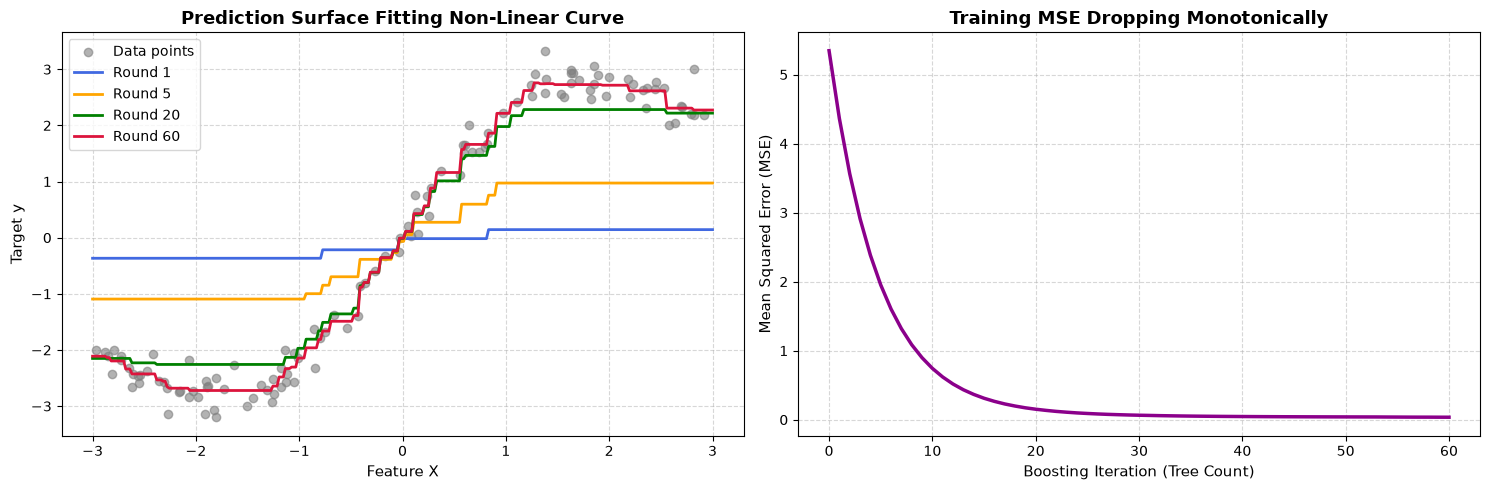

In [9]:
# Dense grid to plot smooth prediction curves
X_grid = np.linspace(-3, 3, 300).reshape(-1, 1)

def predict_at_round(model, X, round_idx):
    res = np.full(X.shape[0], model.f0, dtype=float)
    for t in model.trees[:round_idx]:
        res += model.learning_rate * t.predict(X)
    return res

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.scatter(X_reg, y_reg, color='gray', alpha=0.6, label='Data points', zorder=2)
for r, color in zip([1, 5, 20, 60], ['royalblue', 'orange', 'green', 'crimson']):
    ax1.plot(X_grid, predict_at_round(gb_reg, X_grid, r), label=f'Round {r}', color=color, linewidth=2)
ax1.set_title('Prediction Surface Fitting Non-Linear Curve', fontsize=13, fontweight='bold')
ax1.set_xlabel('Feature X', fontsize=11)
ax1.set_ylabel('Target y', fontsize=11)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(range(len(gb_reg.train_mse)), gb_reg.train_mse, color='darkmagenta', linewidth=2.5)
ax2.set_title('Training MSE Dropping Monotonically', fontsize=13, fontweight='bold')
ax2.set_xlabel('Boosting Iteration (Tree Count)', fontsize=11)
ax2.set_ylabel('Mean Squared Error (MSE)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Prediction Surface):**
  * **Axes:** The horizontal axis is feature $X$, and the vertical axis is target $y$. Gray dots are the training data points.
  * **Curves:** At `Round 1` (blue), the model is just a simple step function with two flat segments. At `Round 5` (orange), it begins bending. By `Round 20` (green) and `Round 60` (crimson), the step-like pieces assemble into a smooth, expressive non-linear curve that tightly captures the true sine wave pattern.
  * **Good vs. Bad:** A good result is a smooth curve tracing the central density of points without sharp spikes chasing individual outliers.
* **Right Plot (Training MSE):**
  * **Axes:** The horizontal axis is the boosting iteration ($0$ to $60$), and the vertical axis is MSE.
  * **Takeaway:** Notice the rapid early drop from $\approx 2.5$ down to $\approx 0.1$, followed by diminishing returns. Each added tree makes smaller and smaller refinements.


---
### Concept 2.2: Extending to Binary Classification with Log-Loss

Now we take the leap into classification! How do we do gradient boosting when the target is binary ($y \in \{0, 1\}$)?

#### 1. The Idea in ONE Plain Sentence
We keep our tree ensemble predicting unconstrained **log-odds** (numbers from $-\infty$ to $+\infty$), turn those log-odds into probabilities using the **sigmoid** function, and train each new tree on the difference between the true label and the predicted probability ($y - p$).

#### 2. Real-Life Analogy
Imagine a doctor assessing whether a patient has a condition (Yes = 1, No = 0).
* The doctor maintains a running "suspicion meter" on a scale of $-\infty$ to $+\infty$.
* At the start, the doctor's suspicion is calibrated to the general prevalence in the population (e.g., if 20% of people have it, baseline log-odds = $\ln(0.2 / 0.8) \approx -1.38$).
* When a blood test comes back abnormal, the doctor adds $+1.5$ to the suspicion meter.
* If a scan is clear, the doctor subtracts $-0.8$.
* To tell the patient their risk, the doctor converts the suspicion meter into a clean probability percentage ($0\%$ to $100\%$).

#### 3. 5-Line Refresher on Sigmoid and Log-Loss
* **Sigmoid Function:** Maps any real number $z$ into a valid probability $p \in (0, 1)$:
  $$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
* **Log-Odds (Logit):** The inverse of sigmoid; expresses probability as an unconstrained score:
  $$z = \ln\left(\frac{p}{1 - p}\right)$$
* **Binary Cross-Entropy (Log-Loss):**
  $$L(y, p) = -[y \ln(p) + (1 - y) \ln(1 - p)]$$
* **Negative Gradient (The Pseudo-Residual):**
  Take the derivative of $L$ with respect to the raw score $z$:
  $$-\frac{\partial L}{\partial z} = y - p$$
  **Look how clean and beautiful that is:** The negative gradient is simply the true class ($0$ or $1$) minus the current predicted probability ($p$)!
* **Optimal Leaf Value (Newton-Raphson Step):**
  Because the sigmoid is non-linear, Jerome Friedman proved that the optimal output $\gamma_j$ for leaf $j$ is:
  $$\gamma_j = \frac{\sum_{i \in \text{Leaf } j} (y_i - p_i)}{\sum_{i \in \text{Leaf } j} p_i(1 - p_i)}$$
  * Numerator: Sum of residuals in the leaf.
  * Denominator: Sum of variances ($p(1-p)$) in the leaf.

#### 4. Common Beginner Mistake
> **Mistake:** Trying to fit classification trees directly to $0$ and $1$ labels using classification decision trees.
> **Reality:** Gradient boosting for classification **still uses regression trees**! The regression trees predict continuous log-odds updates $\gamma$, which are converted to probabilities by the sigmoid function.

#### 5. Quick Check Yourself
> **Question:** If a customer actually churned ($y = 1$) and our model currently gives them only a $20\%$ chance ($p = 0.20$), what is the pseudo-residual?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Pseudo-residual $r = y - p = 1.0 - 0.20 = +0.80$. The positive residual tells the next tree to push this customer's score higher!
> </details>


### Implementing CustomGradientBoostingClassifier
We now implement the classifier from scratch. First, we define a numerically stable sigmoid function.


In [10]:
def sigmoid(z):
    """Numerically stable sigmoid function to prevent overflow."""
    clipped_z = np.clip(z, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-clipped_z))

class CustomGradientBoostingClassifier:
    """Gradient Boosting Classifier for Binary Log-Loss."""
    def __init__(self, n_estimators=40, learning_rate=0.1, max_depth=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []
        self.leaf_gammas = []
        self.f0 = None
        self.train_loss = []


Now we implement the `fit` method for classification: initialize with log-odds, compute residuals ($y - p$), fit regression trees, and calculate optimal leaf values $\gamma$.


In [11]:
def fit_classifier(self, X, y):
    # Initial log-odds based on overall positive class proportion
    p_baseline = np.clip(np.mean(y), 1e-6, 1.0 - 1e-6)
    self.f0 = float(np.log(p_baseline / (1.0 - p_baseline)))
    F = np.full(X.shape[0], self.f0, dtype=float)
    
    for m in range(self.n_estimators):
        p = sigmoid(F)
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        self.train_loss.append(float(loss))
        residuals = y - p
        
        tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=m)
        tree.fit(X, residuals)
        leaf_ids = tree.apply(X)
        gamma_dict = {}
        for lid in np.unique(leaf_ids):
            mask = (leaf_ids == lid)
            gamma_dict[lid] = float(np.sum(residuals[mask]) / (np.sum(p[mask] * (1.0 - p[mask])) + 1e-10))
        
        self.trees.append(tree)
        self.leaf_gammas.append(gamma_dict)
        F += self.learning_rate * np.array([gamma_dict[lid] for lid in leaf_ids])
    return self

CustomGradientBoostingClassifier.fit = fit_classifier


Now we implement `predict_proba` and `predict` methods to generate probability estimates and hard class predictions.


In [12]:
def predict_proba_classifier(self, X):
    F = np.full(X.shape[0], self.f0, dtype=float)
    for tree, gamma_dict in zip(self.trees, self.leaf_gammas):
        leaf_ids = tree.apply(X)
        F += self.learning_rate * np.array([gamma_dict.get(lid, 0.0) for lid in leaf_ids])
    p = sigmoid(F)
    return np.column_stack([1.0 - p, p])

def predict_classifier(self, X):
    return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

CustomGradientBoostingClassifier.predict_proba = predict_proba_classifier
CustomGradientBoostingClassifier.predict = predict_classifier


Now let's test our classifier on a challenging non-linear dataset: the 2D "Two Moons" classification problem.


In [13]:
from sklearn.datasets import make_moons

# Create 2D non-linear classification dataset
X_clf, y_clf = make_moons(n_samples=300, noise=0.25, random_state=42)

# Fit custom classifier
gb_clf = CustomGradientBoostingClassifier(n_estimators=40, learning_rate=0.15, max_depth=2)
gb_clf.fit(X_clf, y_clf)
acc = np.mean(gb_clf.predict(X_clf) == y_clf)
print(f"Custom GB Classifier Training Accuracy: {acc * 100:.2f}%")
print(f"Initial Log-Loss: {gb_clf.train_loss[0]:.4f} -> Final Log-Loss: {gb_clf.train_loss[-1]:.4f}")


Custom GB Classifier Training Accuracy: 95.00%
Initial Log-Loss: 0.6931 -> Final Log-Loss: 0.1503


Now let's visualize the non-linear decision boundary learned by our custom classifier, alongside its log-loss learning curve.


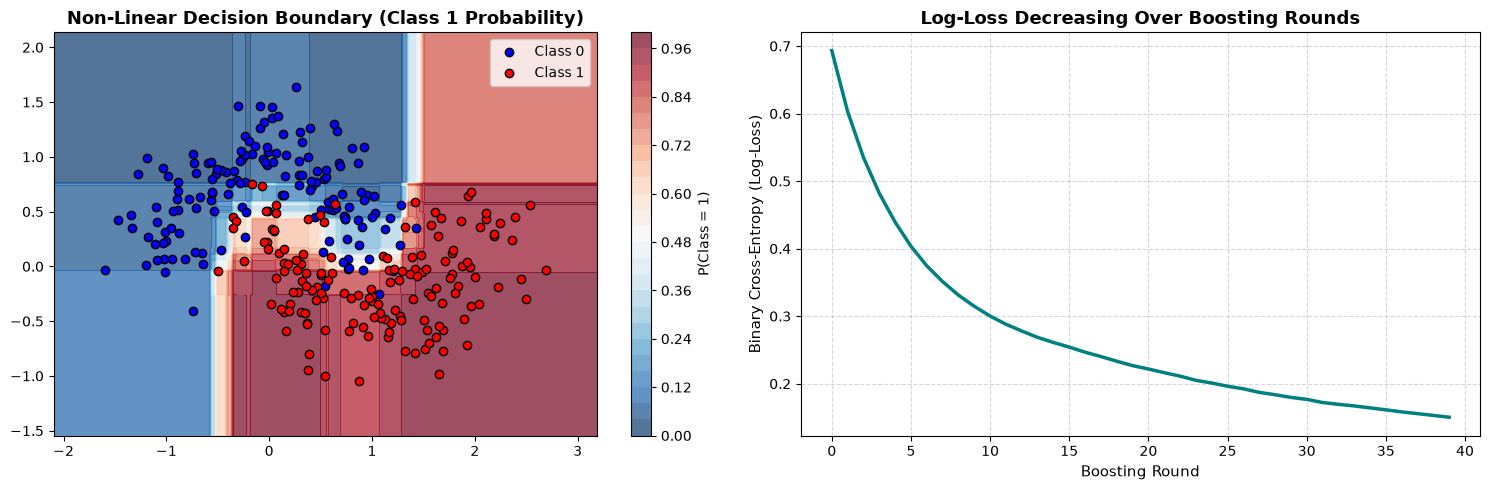

In [14]:
# Create a 2D mesh grid to visualize decision boundary
x_min, x_max = X_clf[:, 0].min() - 0.5, X_clf[:, 0].max() + 0.5
y_min, y_max = X_clf[:, 1].min() - 0.5, X_clf[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = gb_clf.predict_proba(grid_points)[:, 1].reshape(xx.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
# Contour plot of probability landscape
contour = ax1.contourf(xx, yy, probs, levels=25, cmap='RdBu_r', alpha=0.7)
ax1.scatter(X_clf[y_clf == 0, 0], X_clf[y_clf == 0, 1], color='blue', edgecolors='k', label='Class 0')
ax1.scatter(X_clf[y_clf == 1, 0], X_clf[y_clf == 1, 1], color='red', edgecolors='k', label='Class 1')
ax1.set_title('Non-Linear Decision Boundary (Class 1 Probability)', fontsize=13, fontweight='bold')
plt.colorbar(contour, ax=ax1, label='P(Class = 1)')
ax1.legend()

# Log-Loss trajectory
ax2.plot(range(len(gb_clf.train_loss)), gb_clf.train_loss, color='teal', linewidth=2.5)
ax2.set_title('Log-Loss Decreasing Over Boosting Rounds', fontsize=13, fontweight='bold')
ax2.set_xlabel('Boosting Round', fontsize=11)
ax2.set_ylabel('Binary Cross-Entropy (Log-Loss)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Decision Boundary Landscape):**
  * **Axes:** $X_0$ and $X_1$ are the two features of the moon dataset. Blue circles are Class 0, and red circles are Class 1.
  * **Color Shading:** Blue regions represent predicted $P(\text{Class}=1) \approx 0$, while red regions represent $P(\text{Class}=1) \approx 1$. The soft white/pink transition zone is the decision boundary ($P = 0.5$). Notice how smoothly the boundary weaves between the interlocking moons without overfitting individual noisy outliers.
* **Right Plot (Log-Loss Curve):**
  * **Axes:** Horizontal axis is the boosting iteration, vertical axis is Binary Cross-Entropy.
  * **Takeaway:** The curve drops smoothly from $\approx 0.69$ (random guessing on balanced data) down to $\approx 0.22$. This confirms that our custom leaf gamma calculations and gradient updates are mathematically correct!

---

### Step 2 Recap in 3 Bullets
1. We implemented gradient boosting from scratch for regression: baseline is the target mean, weak learners fit residuals ($y - \hat{y}$), and updates are scaled by learning rate $\eta$.
2. For binary classification, gradient boosting still uses **regression trees** operating on log-odds; the pseudo-residual is the difference between actual label and predicted probability ($y - p$).
3. The optimal leaf value $\gamma$ in classification divides the sum of residuals by the sum of variances ($p(1-p)$), creating a stable Newton-Raphson step that drives log-loss down monotonically.

> **If you remember only one thing:**
> Gradient boosting is completely modular: swap the loss function, compute its negative gradient ($r$), and your trees will naturally learn to optimize it!
